<a href="https://colab.research.google.com/github/Alister44/melbourne-housing-price-prediction/blob/main/notebooks/housing_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
RANDOM_STATE = 42


#  Data Preparation & Cleaning (Python)

## Loading raw data

In [2]:
FILE_IN = 'https://raw.githubusercontent.com/Alister44/melbourne-housing-price-prediction/refs/heads/main/data/melb_data_raw.csv'
df_raw = pd.read_csv(FILE_IN)
df = df_raw.copy()

## Removing the technical column (if present)

In [3]:
# drop the technical index column if it exists
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [4]:
pd.set_option("display.max_columns", None)
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## Check for missing values

In [5]:
def info_types_missVals():
    return pd.DataFrame({
        "dtype": df.dtypes,
        "missing count": df.isnull().sum(),
        "missing (%)": (df.isna().mean() * 100).round(2)
    }).sort_values("missing (%)", ascending=False)

info_types_missVals()

,dtype,missing count,missing (%)
BuildingArea,float64,6450,47.50
YearBuilt,float64,5375,39.58
CouncilArea,object,1369,10.08
Car,float64,62,0.46
Suburb,object,0,0.00
Price,float64,0,0.00
Type,object,0,0.00
Rooms,int64,0,0.00
Address,object,0,0.00
Distance,float64,0,0.00


## Convert data types

In [6]:
df['Date'] = pd.to_datetime(df['Date'],errors='coerce', dayfirst=True)
df['YearBuilt'] = df['YearBuilt'].astype('Int32')
df['Rooms'] = df['Rooms'].astype('Int8')
df['Bedroom2'] = df['Bedroom2'].astype('Int8')
df['Bathroom'] = df['Bathroom'].astype('Int8')
df['Car'] = df['Car'].astype('Int8')
df['Propertycount'] = df['Propertycount'].astype('Int64')

In [7]:
info_types_missVals()

,dtype,missing count,missing (%)
BuildingArea,float64,6450,47.50
YearBuilt,Int32,5375,39.58
CouncilArea,object,1369,10.08
Car,Int8,62,0.46
Suburb,object,0,0.00
Price,float64,0,0.00
Type,object,0,0.00
Rooms,Int8,0,0.00
Address,object,0,0.00
Distance,float64,0,0.00


## EDA (Exploratory Data Analysis)

In [8]:
df.describe() # descriptive statistics of numeric columns

,Rooms,Price,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.0,1.358000e+04,13580,13580.000000,13580.000000,13580.0,13580.0,13518.0,13580.000000,7130.000000,8205.0,13580.000000,13580.000000,13580.0
mean,2.937997,1.075684e+06,2017-01-28 20:25:03.622974976,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
min,1.0,8.500000e+04,2016-01-28 00:00:00,0.000000,3000.000000,0.0,0.0,0.0,0.000000,0.000000,1196.0,-38.182550,144.431810,249.0
25%,2.0,6.500000e+05,2016-09-10 00:00:00,6.100000,3044.000000,2.0,1.0,1.0,177.000000,93.000000,1940.0,-37.856822,144.929600,4380.0
50%,3.0,9.030000e+05,2017-03-04 00:00:00,9.200000,3084.000000,3.0,1.0,2.0,440.000000,126.000000,1970.0,-37.802355,145.000100,6555.0
75%,3.0,1.330000e+06,2017-06-24 00:00:00,13.000000,3148.000000,3.0,2.0,2.0,651.000000,174.000000,1999.0,-37.756400,145.058305,10331.0
max,10.0,9.000000e+06,2017-09-23 00:00:00,48.100000,3977.000000,20.0,8.0,10.0,433014.000000,44515.000000,2018.0,-37.408530,145.526350,21650.0
std,0.955748,6.393107e+05,NaN,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772


In [9]:
df.describe(include='all') # descriptive statistics for all columns

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
count,13580,13580,13580.0,13580,1.358000e+04,13580,13580,13580,13580.000000,13580.000000,13580.0,13580.0,13518.0,13580.000000,7130.000000,8205.0,12211,13580.000000,13580.000000,13580,13580.0
unique,314,13378,<NA>,3,NaN,5,268,NaN,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,33,NaN,NaN,8,<NA>
top,Reservoir,5 Margaret St,<NA>,h,NaN,S,Nelson,NaN,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,Moreland,NaN,NaN,Southern Metropolitan,<NA>
freq,359,3,<NA>,9449,NaN,9022,1565,NaN,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,1163,NaN,NaN,4695,<NA>
mean,NaN,NaN,2.937997,NaN,1.075684e+06,NaN,NaN,2017-01-28 20:25:03.622974976,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,NaN,-37.809203,144.995216,NaN,7454.417378
min,NaN,NaN,1.0,NaN,8.500000e+04,NaN,NaN,2016-01-28 00:00:00,0.000000,3000.000000,0.0,0.0,0.0,0.000000,0.000000,1196.0,NaN,-38.182550,144.431810,NaN,249.0
25%,NaN,NaN,2.0,NaN,6.500000e+05,NaN,NaN,2016-09-10 00:00:00,6.100000,3044.000000,2.0,1.0,1.0,177.000000,93.000000,1940.0,NaN,-37.856822,144.929600,NaN,4380.0
50%,NaN,NaN,3.0,NaN,9.030000e+05,NaN,NaN,2017-03-04 00:00:00,9.200000,3084.000000,3.0,1.0,2.0,440.000000,126.000000,1970.0,NaN,-37.802355,145.000100,NaN,6555.0
75%,NaN,NaN,3.0,NaN,1.330000e+06,NaN,NaN,2017-06-24 00:00:00,13.000000,3148.000000,3.0,2.0,2.0,651.000000,174.000000,1999.0,NaN,-37.756400,145.058305,NaN,10331.0
max,NaN,NaN,10.0,NaN,9.000000e+06,NaN,NaN,2017-09-23 00:00:00,48.100000,3977.000000,20.0,8.0,10.0,433014.000000,44515.000000,2018.0,NaN,-37.408530,145.526350,NaN,21650.0


## Handle outliers and fill missing values (if needed)

### Note to `Method`
The table contains only five sale methods: S, SP, PI, VB and SA.
Only S, SP and SA clearly mean that the sale took place.

- **PI (passed in):** the auction took place, but the property was not sold.
  However, PI rows have a value in the `Date` column (date sold), which is
  a possible contradiction.
- **VB (vendor bid):** the outcome of the deal is not clearly stated, so the
  property may not have been sold. In that case, `Price` may contain the last
  or highest bid rather than the final sale price.

**Decision:** as an analyst, I exclude properties with the ambiguous statuses
PI and VB from the model. The goal of the model is to predict the sale price.
If `Price` for PI and VB may not be the final price, these rows add noise to
the target variable, and the model learns from inaccurate answers.

In [10]:
df['Method'].unique()

array(['S', 'SP', 'PI', 'VB', 'SA'], dtype=object)

In [11]:
df["Method"].value_counts(normalize=True)*100

,proportion
Method,
S,66.435935
SP,12.540501
PI,11.516937
VB,8.829161
SA,0.677467


In [12]:
rows_before = len(df)
rows_before

13580

In [13]:
df = df[~df["Method"].isin(["PI", "VB"])].copy()
rows_removed = rows_before - len(df)

print(f"\nRemoved {rows_removed} rows ({rows_removed / rows_before:.1%} of the data)")
print(f"Rows left: {len(df)}")

# Check: only S, SP and SA should remain
print(df["Method"].unique())


Removed 2763 rows (20.3% of the data)
Rows left: 10817
['S' 'SP' 'SA']


### Note on `Bedroom2`
In 1.5% of rows `Bedroom2` is greater than `Rooms`. `Bedroom2` comes from
a different source, so the difference may reflect different definitions
rather than errors. Since the two columns are almost identical, I kept
`Rooms` and dropped `Bedroom2` (made it in Feature Engeneering). I did not remove any rows.

In [14]:
(df["Bedroom2"] > df["Rooms"]).sum() # number of objects where number of bedrooms more that totaly rooms

np.int64(161)

In [15]:
(df["Bedroom2"] > df["Rooms"]).mean() * 100 # number of objects where number of bedrooms more that totaly rooms

np.float64(1.4883978922067116)

### Note on `Bathroom`
In 28 rows (0.2%) `Bathroom` is greater than `Rooms`. In 23 of them the
difference is 1, which is unusual but possible. In 5 rows the difference is
2 or more. I did not change these rows, because the effect on the model is
negligible and I cannot tell which of the two columns is wrong.

In [16]:
(df["Bathroom"] > df["Rooms"]).mean() * 100 # number of objects where number of Bathroom more that totaly rooms

np.float64(0.18489414810021262)

In [17]:
(df["Bathroom"] > df["Rooms"]).sum()

np.int64(20)

In [18]:

(df["Bathroom"] - df["Rooms"])[df["Bathroom"] > df["Rooms"]].value_counts()

,count
1,17
3,2
2,1


Note to `Car`  
`Car` has 0.43% missing values. I left them unchanged in the cleaning step;
they are imputed with the median inside the pipeline, fitted on the
training data only.

In [19]:
info_types_missVals()

,dtype,missing count,missing (%)
BuildingArea,float64,5193,48.01
YearBuilt,Int32,4360,40.31
CouncilArea,object,1089,10.07
Car,Int8,43,0.40
Suburb,object,0,0.00
Price,float64,0,0.00
Type,object,0,0.00
Rooms,Int8,0,0.00
Address,object,0,0.00
Distance,float64,0,0.00


### Note to `Landsize`
I treat `Landsize` as the plot area of the property, in square meters.
I kept zeros. In Australia it is common for houses, townhouses and duplexes
to come without a private plot of land, so 0 is treated as a real value, not
as missing data. Zeros make up 1.8% of houses, 12.5% of townhouses and 54%
of units.

In [20]:
zero_share = (df["Landsize"] == 0).groupby(df["Type"]).mean() * 100 # Share of properties with Landsize = 0 within each property type (%).
print(zero_share.round(1))

Type
h     1.7
t    13.2
u    51.5
Name: Landsize, dtype: float64


### `BuildingArea`
An area of 0 is not a real measurement, so I replaced X zeros with missing
values. I also replaced 60 values below 15 m² for properties with more than
one room, which is not realistic. Properties with one room and an area of
10-15 m² were kept, because a studio of that size is unusual but possible.
All missing values are imputed with the median in the pipeline.

In [21]:
# A zero building area is not a real value, so I treat it as missing.
# Landsize = 0 is kept, because a property can have no land of its own.
print((df["BuildingArea"] == 0).sum())   # number of zeros
df["BuildingArea"] = df["BuildingArea"].replace(0, np.nan)

14


In [22]:
# A building area below 15 m² is not realistic for a property with more
# than one room, so I treat it as a data error and set it to missing.
mask = (df["BuildingArea"] < 15) & (df["Rooms"] > 1)
print(mask.sum())   # how many values are affected
df.loc[mask, "BuildingArea"] = np.nan

41


In [23]:
info_types_missVals()

,dtype,missing count,missing (%)
BuildingArea,float64,5248,48.52
YearBuilt,Int32,4360,40.31
CouncilArea,object,1089,10.07
Car,Int8,43,0.40
Suburb,object,0,0.00
Price,float64,0,0.00
Type,object,0,0.00
Rooms,Int8,0,0.00
Address,object,0,0.00
Distance,float64,0,0.00


### Note to `YearBuilt`

We check whether the YearBuilt is specified correctly and display a few rows in ascending order. We see that 1196 is clearly an error. Next comes 1830, which looks more plausible.

In [24]:
df['YearBuilt'].sort_values().head()

,YearBuilt
2079,1830
2554,1850
4843,1850
5405,1850
2530,1854


In [25]:
df.loc[df['YearBuilt'] == 1196, 'YearBuilt'] = pd.NA # replaced "1196" with NA
df['YearBuilt'].sort_values(ascending=False).head()#checked for any erroneous maximum date

,YearBuilt
1234,2018
8134,2017
12629,2017
5153,2017
4282,2017


## Duplicate check

In [26]:
print(f"Duplicates: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)
print(f"Duplicates after removal: {df.duplicated().sum()}")

Duplicates: 0
Duplicates after removal: 0


## EDA 2.0

The goal is to understand the data before modeling.

1. distribution of the target variable `Price` (whether it is symmetric or skewed; what this implies for the model)

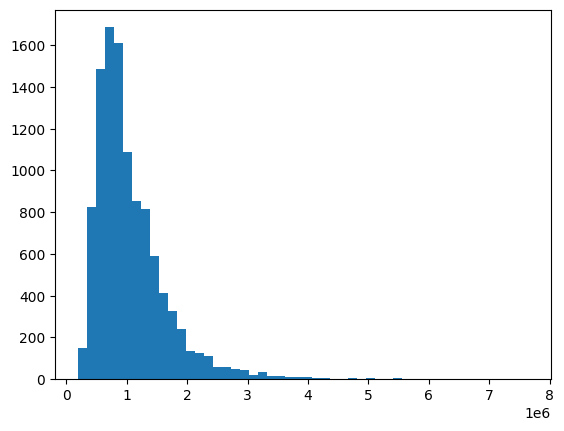

In [27]:
plt.hist(df["Price"], bins=50)
plt.show()

Price distribution

The histogram shows that the target variable Price is strongly right-skewed. Most properties are priced between roughly AUD 0.5 and 1.5 million, while a long tail of expensive properties extends up to about AUD 8 million.

Such skewness can be a problem for linear regression: the few very expensive properties produce large errors that dominate training, and the residuals are unlikely to be normally distributed. Tree-based models such as Random Forest are less sensitive to this, since they make no assumptions about the distribution of the target.

To address this, I created a log-transformed target, log_price = np.log10(Price), which brings the distribution close to normal (see histogram below). The linear regression model is trained on log_price, and its predictions are converted back to the original scale with 10 ** prediction before evaluation.

In [28]:
df["log_price"] = np.log10(df["Price"])

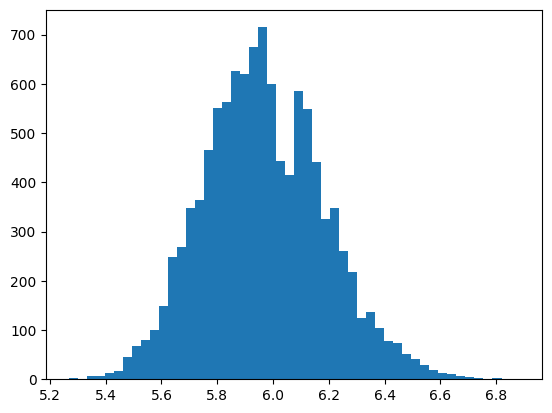

In [29]:
plt.hist(df["log_price"], bins=50)
plt.show()

2. How price depends on `Regionname` and `Type`

The logic is simple: if the boxes for different categories are positioned at different heights, it means the price depends on that feature. For example, houses (h) are typically significantly more expensive than apartments (u), and this is immediately apparent on the graph. If all the boxes were at the same level, it would indicate that the feature has little to no effect on the price.

<Axes: title={'center': 'log_price'}, xlabel='Type'>

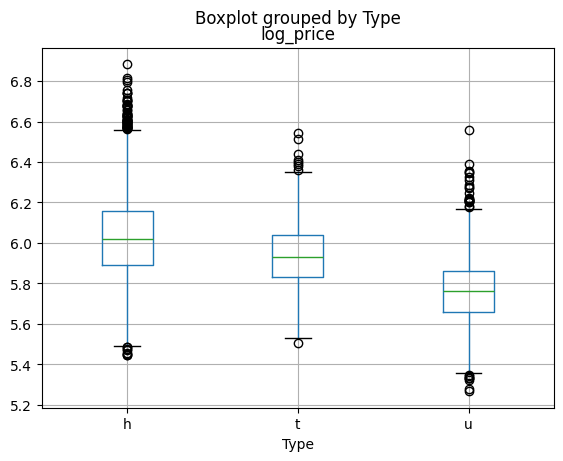

In [30]:
df.boxplot(column="log_price", by="Type")

The boxplot of log_price by property type shows a clear relationship between type and price. Houses (h) are the most expensive, with a median price of about AUD 1.05 million, followed by townhouses (t, about AUD 850,000) and units (u, about AUD 575,000).

The price ranges of houses and townhouses partly overlap, while units are noticeably cheaper than both. Houses also show the widest spread and the largest number of high-price outliers, which correspond to the long right tail observed in the price distribution.

Since property type clearly affects price, Type will be included as a feature in the model using one-hot encoding.

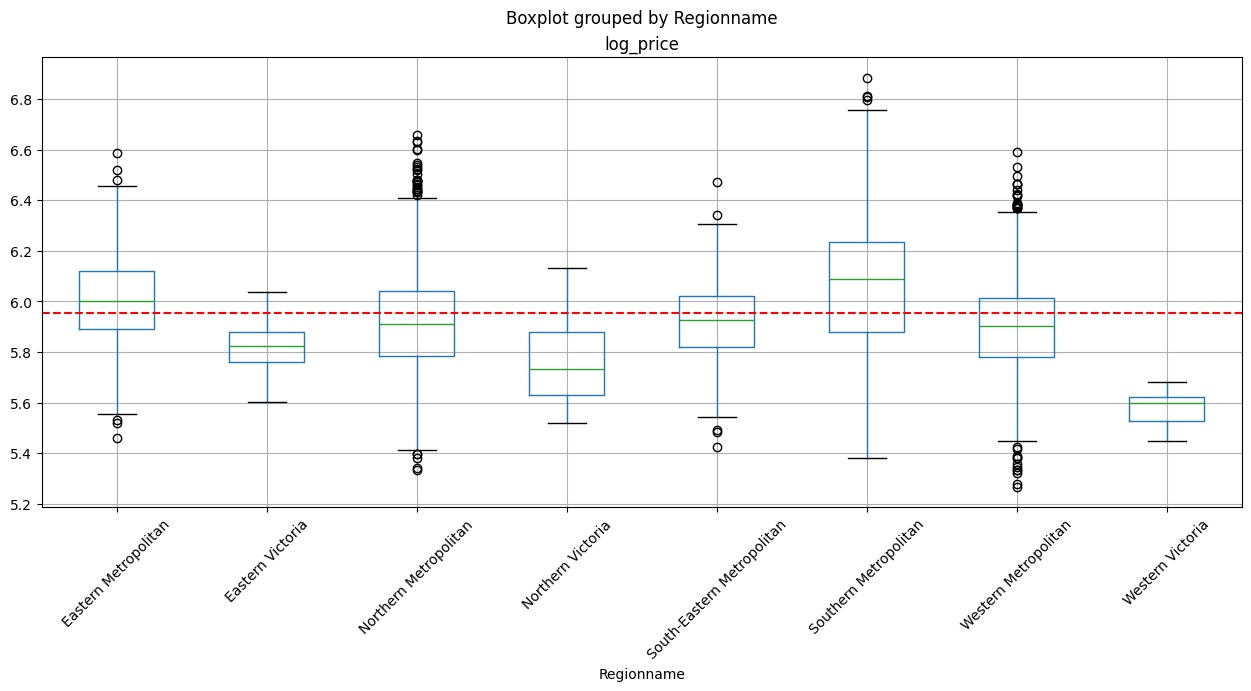

In [31]:
ax = df.boxplot(column="log_price", by="Regionname", figsize=(15, 6), rot=45,grid=True)
ax.axhline(df['log_price'].median(), color='red', linestyle='--')
plt.show()

The medians of log_price vary noticeably between regions, which indicates that price also depends on location. Southern Metropolitan is the most expensive region, while the regional areas of Victoria are the cheapest.

3. correlation of numeric features with `Price`

In [32]:
num = df.select_dtypes("number")
num.corr()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount,log_price
Rooms,1.000000,0.459353,0.303479,0.056182,0.951847,0.572642,0.393177,0.073027,0.111788,-0.036041,0.023182,0.081634,-0.072362,0.513849
Price,0.459353,1.000000,-0.190099,0.092059,0.440855,0.419880,0.198850,0.035708,0.075730,-0.352276,-0.219714,0.196340,-0.038708,0.933312
Distance,0.303479,-0.190099,1.000000,0.451747,0.309955,0.144351,0.266665,0.115612,0.101020,0.281240,-0.129651,0.233727,-0.040283,-0.192764
Postcode,0.056182,0.092059,0.451747,1.000000,0.062505,0.116303,0.049699,0.091764,0.056932,0.049445,-0.374616,0.438906,0.064933,0.072932
Bedroom2,0.951847,0.440855,0.309955,0.062505,1.000000,0.571024,0.393568,0.072683,0.110689,-0.018213,0.024621,0.084852,-0.069889,0.493082
Bathroom,0.572642,0.419880,0.144351,0.116303,0.571024,1.000000,0.300224,0.062086,0.100691,0.188473,-0.064048,0.106992,-0.042606,0.411526
Car,0.393177,0.198850,0.266665,0.049699,0.393568,0.300224,1.000000,0.093034,0.092174,0.140442,0.003245,0.053642,-0.014687,0.213875
Landsize,0.073027,0.035708,0.115612,0.091764,0.072683,0.062086,0.093034,1.000000,0.524652,0.037412,0.028477,0.027376,-0.014500,0.037532
BuildingArea,0.111788,0.075730,0.101020,0.056932,0.110689,0.100691,0.092174,0.524652,1.000000,0.031933,0.049644,-0.032001,-0.028422,0.080470
YearBuilt,-0.036041,-0.352276,0.281240,0.049445,-0.018213,0.188473,0.140442,0.037412,0.031933,1.000000,0.062181,0.002820,0.009094,-0.388462


In [33]:
num.corr()["log_price"]

,log_price
Rooms,0.513849
Price,0.933312
Distance,-0.192764
Postcode,0.072932
Bedroom2,0.493082
Bathroom,0.411526
Car,0.213875
Landsize,0.037532
BuildingArea,0.080470
YearBuilt,-0.388462


In [34]:
(num.corr()["log_price"]
.drop(["log_price","Price","Postcode"])
.sort_values(key=abs, ascending=False))

,log_price
Rooms,0.513849
Bedroom2,0.493082
Bathroom,0.411526
YearBuilt,-0.388462
Longtitude,0.238392
Lattitude,-0.235770
Car,0.213875
Distance,-0.192764
BuildingArea,0.080470
Propertycount,-0.057950


The number of rooms (0.51) and bathrooms (0.41) show the strongest relationship with price. There is also a noticeable negative correlation with the year of construction (−0.39): older properties tend to be more expensive, probably because they are located in prestigious areas closer to the city centre.

Surprisingly, land size (Landsize) and building area (BuildingArea) are only weakly correlated with price. For Landsize, a possible reason is that units have practically no land of their own, so if the correlation were calculated separately for houses and units, it would likely be stronger for houses. In addition, both columns contain outliers and missing values, and Pearson correlation is very sensitive to such issues.

Correlation on complete rows only

By default, corr() handles missing values pairwise, so each correlation is calculated on a different subset of rows. To check whether missing data distorts the results, I recalculated the correlations with log_price using only rows without any missing values. This makes all coefficients comparable, as they are based on the same set of observations.

In [35]:
df_drop = df.copy()
df_drop = df_drop.dropna()
print("before drop:", df.shape)
print("after drop:", df_drop.shape)

num = df_drop.select_dtypes("number")

(num.corr()["log_price"]
    .drop(["log_price", "Price", "Postcode"])
    .sort_values(key=abs, ascending=False)
    .round(3))

before drop: (10817, 22)
after drop: (4868, 22)


,log_price
Rooms,0.561
Bedroom2,0.538
BuildingArea,0.483
Bathroom,0.453
YearBuilt,-0.382
Lattitude,-0.237
Longtitude,0.236
Car,0.229
Distance,-0.182
Propertycount,-0.070


When the correlation is calculated only on complete rows (4,868 of 10,817), the correlation between `BuildingArea` and `log_price` rises from 0.08 to 0.48. This shows that building area is in fact strongly related to price, and its weak correlation on the full data was caused by missing and erroneous values. The other correlations remain stable, while `Landsize` stays weak. Since dropping incomplete rows removes 55% of the data, missing values are imputed instead of dropped for model training.

# Feature engineering

Feature engineering means creating new, useful columns from existing ones. A model only sees the features it is given, so it is worth making useful signals explicit:

* **Property age** = year of sale minus year built. This is often more informative than the year built itself.
* **Date components** (year and month of sale), because the housing market changes over time.
* **Missing-value indicator**: a new 0/1 column showing whether a value has (1) or not (0). Sometimes the fact that a value is missing carries information in itself.
* **Frequency encoding of suburbs**: instead of hundreds of columns, one for each suburb, a single column showing how often each suburb occurs in the data.

In [36]:
fe = df.copy()
# Date components
fe['sale_year'] = fe["Date"].dt.year
fe['sale_month'] = fe['Date'].dt.month

In [37]:
# Property age
fe['age'] = fe['sale_year'] - fe['YearBuilt']
fe['age'].head()

,age
0,<NA>
1,116
2,117
5,<NA>
6,106


In [38]:
fe.describe()

,Rooms,Price,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount,log_price,sale_year,sale_month,age
count,10817.0,1.081700e+04,10817,10817.000000,10817.000000,10817.0,10817.0,10774.0,10817.000000,5569.000000,6457.0,10817.000000,10817.000000,10817.0,10817.000000,10817.000000,10817.000000,6457.0
mean,2.919386,1.057294e+06,2017-01-31 21:37:49.427752704,10.439198,3104.867986,2.89535,1.492558,1.597364,522.835167,152.328335,1964.448815,-37.807754,144.993452,7428.034853,5.967638,2016.541925,7.050476,52.057302
min,1.0,1.850000e+05,2016-01-28 00:00:00,0.000000,3000.000000,0.0,0.0,0.0,0.000000,1.000000,1830.0,-38.182550,144.431810,249.0,5.267172,2016.000000,1.000000,-2.0
25%,2.0,6.550000e+05,2016-09-10 00:00:00,6.300000,3044.000000,2.0,1.0,1.0,185.000000,95.000000,1940.0,-37.857000,144.925410,4217.0,5.816241,2016.000000,5.000000,19.0
50%,3.0,9.000000e+05,2017-03-04 00:00:00,9.700000,3081.000000,3.0,1.0,2.0,448.000000,125.000000,1970.0,-37.800010,144.998840,6543.0,5.954243,2017.000000,7.000000,47.0
75%,3.0,1.301000e+06,2017-06-24 00:00:00,13.300000,3147.000000,3.0,2.0,2.0,650.000000,168.000000,1997.0,-37.752450,145.058500,10331.0,6.114277,2017.000000,9.000000,76.0
max,8.0,7.650000e+06,2017-09-23 00:00:00,48.100000,3977.000000,9.0,7.0,10.0,76000.000000,44515.000000,2018.0,-37.408530,145.526350,21650.0,6.883661,2017.000000,12.000000,186.0
std,0.91005,6.019354e+05,NaN,6.074371,94.447972,0.911158,0.65368,0.94984,1411.007371,609.678416,35.863696,0.081819,0.107840,4435.254655,0.217159,0.498262,2.544472,35.789928


A negative number appeared in one of the ages. We replace it with np.nan.

In [39]:
fe.loc[fe['age']<0,'age'] = np.nan

In [40]:
fe.describe()['age']

,age
count,6451.0
mean,52.106805
min,0.0
25%,19.0
50%,47.0
75%,76.0
max,186.0
std,35.769719


In [41]:
# Missing-value indicator
fe["has_buildingarea"] = fe["BuildingArea"].notna().astype(int)
fe["has_yearbuilt"] = fe["YearBuilt"].notna().astype(int)
fe[["has_buildingarea","has_yearbuilt"]].head()

,has_buildingarea,has_yearbuilt
0,0,0
1,1,1
2,1,1
5,0,0
6,1,1


In [42]:
# Frequency encoding of suburbs
fe["suburb_freq"] = fe["Suburb"].map(fe["Suburb"].value_counts())

In [43]:
fe["Suburb"].value_counts()

,count
Suburb,
Reservoir,305
Richmond,206
Bentleigh East,198
Preston,189
Brunswick,170
...,...
Wallan,1
Mount Evelyn,1
New Gisborne,1


In [44]:
fe.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,log_price,sale_year,sale_month,age,has_buildingarea,has_yearbuilt,suburb_freq
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,2016-12-03,2.5,3067.0,2,1,1,202.0,NaN,<NA>,Yarra,-37.7996,144.9984,Northern Metropolitan,4019,6.170262,2016,12,<NA>,0,0,47
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,2016-02-04,2.5,3067.0,2,1,0,156.0,79.0,1900,Yarra,-37.8079,144.9934,Northern Metropolitan,4019,6.014940,2016,2,116,1,1,47
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,2017-03-04,2.5,3067.0,3,2,0,134.0,150.0,1900,Yarra,-37.8093,144.9944,Northern Metropolitan,4019,6.165838,2017,3,117,1,1,47
5,Abbotsford,129 Charles St,2,h,941000.0,S,Jellis,2016-05-07,2.5,3067.0,2,1,0,181.0,NaN,<NA>,Yarra,-37.8041,144.9953,Northern Metropolitan,4019,5.973590,2016,5,<NA>,0,0,47
6,Abbotsford,124 Yarra St,3,h,1876000.0,S,Nelson,2016-05-07,2.5,3067.0,4,2,0,245.0,210.0,1910,Yarra,-37.8024,144.9993,Northern Metropolitan,4019,6.273233,2016,5,106,1,1,47


In [45]:
# Remove unnecessary columns:
#    - Bedroom2 duplicates Rooms (the two are highly correlated)
#    - Address, SellerG and Suburb are text columns with too many unique values
#      and are not encoded (Suburb is replaced by its frequency encoding)
#    - Postcode is a location code, already covered by Regionname and coordinates
#    - Date and YearBuilt are replaced by the engineered features
#      (sale year, sale month and property age)
drop_cols = ['Bedroom2', 'Address', 'Suburb', 'Postcode', 'Date', 'YearBuilt', 'SellerG']
fe = fe.drop(columns=drop_cols)

# Preparation to Modeling

In this step, I prepare the data for training:

* define the target `y` and the features `X`;
* split the features into numerical and categorical ones;
* encode the categorical features (One-Hot encoding for nominal features, taking high cardinality into account);
* combine all preprocessing steps into a single pipeline, so they are applied in the same way to the training and test sets;
* split the data into training and test sets.

### Why these steps are needed

A model only accepts numbers and cannot handle missing values, so the data has to be prepared first:

* **X and y.** `y` is the value to be predicted. Since the price distribution is strongly right-skewed, I use `log_price = log10(Price)` as the target. `X` contains all features used for the prediction (without `Price` and `log_price`).
* **Train and test split.** The data is divided into two parts: the model learns on the training set, and its performance is evaluated on the test set, which it has never seen. The key rule is never to evaluate a model on the same data it was trained on.
* **Encoding categorical features.** Text values, such as property type, are converted into numbers. One-Hot encoding creates a separate 0/1 column for each category. For features with a very large number of unique values, such as `Suburb`, One-Hot encoding is not suitable, so frequency encoding was used instead in the Feature Engineering step.
* **Imputing missing values within the pipeline.** Missing numerical values are filled with the median, and missing categorical values with the most frequent category.
* **Pipeline.** A pipeline combines all preprocessing steps and the model into a single object. It ensures that preprocessing is learned only from the training data and applied in the same way to the test data, which prevents data leakage.

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer          # filling in missing values
from sklearn.preprocessing import OneHotEncoder   # encoding categories

In [48]:
y = fe['log_price']
X = fe.drop(columns=['log_price', 'Price'])

In [51]:
X.head()

,Rooms,Type,Method,Distance,Bathroom,Car,Landsize,BuildingArea,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,sale_year,sale_month,age,has_buildingarea,has_yearbuilt,suburb_freq
0,2,h,S,2.5,1,1,202.0,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019,2016,12,<NA>,0,0,47
1,2,h,S,2.5,1,0,156.0,79.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019,2016,2,116,1,1,47
2,3,h,SP,2.5,2,0,134.0,150.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019,2017,3,117,1,1,47
5,2,h,S,2.5,1,0,181.0,NaN,Yarra,-37.8041,144.9953,Northern Metropolitan,4019,2016,5,<NA>,0,0,47
6,3,h,S,2.5,2,0,245.0,210.0,Yarra,-37.8024,144.9993,Northern Metropolitan,4019,2016,5,106,1,1,47


In [52]:
# split the features into numerical and categorical ones
cat_cols = ['Type','Method','Regionname','CouncilArea']
num_cols = [c for c in X.columns if c not in cat_cols]


In [54]:
fe[cat_cols].isna().sum()

,0
Type,0
Method,0
Regionname,0
CouncilArea,1089


In [55]:
fe[num_cols].isna().sum()

,0
Rooms,0
Distance,0
Bathroom,0
Car,43
Landsize,0
BuildingArea,5248
Lattitude,0
Longtitude,0
Propertycount,0
sale_year,0


In [57]:
# Define preprocessing with ColumnTransformer:
#    - numerical features: fill missing values with the median
#    - categorical features: fill missing values with the most frequent value,
#      then apply One-Hot encoding (unknown categories in the test set are ignored)
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))]),
    cat_cols)
])

In [59]:
# 4) Split the data into training and test sets
#    (80% train, 20% test; random_state ensures reproducible results)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print("Numerical features:", num_cols)
print("Categorical features:", cat_cols)

Train: 8653 Test: 2164
Numerical features: ['Rooms', 'Distance', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'Lattitude', 'Longtitude', 'Propertycount', 'sale_year', 'sale_month', 'age', 'has_buildingarea', 'has_yearbuilt', 'suburb_freq']
Categorical features: ['Type', 'Method', 'Regionname', 'CouncilArea']
